Задача 1

Обучаващо: 1077 Валидационно: 360 Тестово: 360
k-NN: train accuracy = 0.9907, validation accuracy = 0.9806
SVM: train accuracy = 0.9963, validation accuracy = 0.9972
MLP: train accuracy = 1.0000, validation accuracy = 0.9806


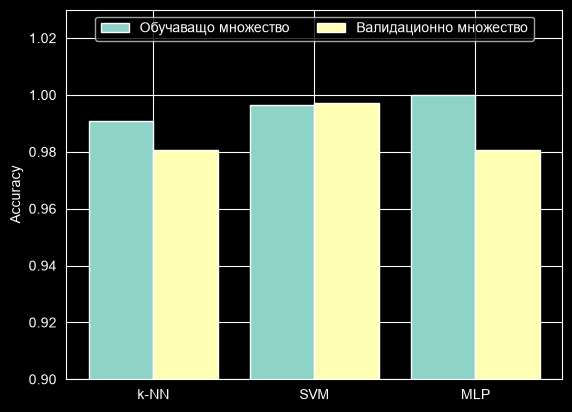

SVM test accuracy: 0.9917


In [15]:
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

digits = datasets.load_digits()
X, y = digits.data, digits.target

# Тестово множество (20%), след това валидационно множество (20%)
X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_trainval, y_trainval, test_size=0.25,
                                                  stratify=y_trainval, random_state=42)
print("Обучаващо:", len(X_train), "Валидационно:", len(X_val), "Тестово:", len(X_test))

# Модели с хиперпараметри по подразбиране
models = {
    'k-NN': Pipeline([('scaler', MinMaxScaler()), ('clf', KNeighborsClassifier())]),
    'SVM': Pipeline([('scaler', MinMaxScaler()), ('clf', SVC())]),
    'MLP': Pipeline([('scaler', MinMaxScaler()), ('clf', MLPClassifier(max_iter=1000, random_state=42))]),
}

names, train_scores, val_scores = [], [], []

for name, model in models.items():
    model.fit(X_train, y_train)
    train_acc = accuracy_score(y_train, model.predict(X_train))
    val_acc = accuracy_score(y_val, model.predict(X_val))
    names.append(name)
    train_scores.append(train_acc)
    val_scores.append(val_acc)
    print(f"{name}: train accuracy = {train_acc:.4f}, validation accuracy = {val_acc:.4f}")

x = range(len(names))
plt.bar([i - 0.2 for i in x], train_scores, width=0.4, label='Обучаващо множество')
plt.bar([i + 0.2 for i in x], val_scores, width=0.4, label='Валидационно множество')
plt.xticks(x, names)
plt.ylim(0.9, 1.03)
plt.ylabel('Accuracy')
plt.legend(loc='upper center', ncol=2)
plt.show()

svm_model = models['SVM']
svm_model.fit(X_trainval, y_trainval)
y_pred = svm_model.predict(X_test)
print(f"SVM test accuracy: {round(accuracy_score(y_test, y_pred), 4)}")

Най-голямата разлика е при MLP. Проблемът е, че моделът се е overfit-нал на обучаващите данни, но не може да класифицира толкова добре невиждани. Най-добър е резултатът при SVM, където валидацинната точност дори изпреварва тази върху обучаващите данни.

Задача 2

k =  1: train accuracy = 1.0000, validation accuracy = 0.9889
k =  2: train accuracy = 0.9916, validation accuracy = 0.9806
k =  3: train accuracy = 0.9926, validation accuracy = 0.9806
k =  4: train accuracy = 0.9907, validation accuracy = 0.9778
k =  5: train accuracy = 0.9907, validation accuracy = 0.9806
k =  6: train accuracy = 0.9889, validation accuracy = 0.9778
k =  7: train accuracy = 0.9889, validation accuracy = 0.9778
k =  8: train accuracy = 0.9861, validation accuracy = 0.9750
k =  9: train accuracy = 0.9842, validation accuracy = 0.9750
k = 10: train accuracy = 0.9805, validation accuracy = 0.9750
k = 11: train accuracy = 0.9824, validation accuracy = 0.9750
k = 12: train accuracy = 0.9814, validation accuracy = 0.9722
k = 13: train accuracy = 0.9805, validation accuracy = 0.9750
k = 14: train accuracy = 0.9777, validation accuracy = 0.9694
k = 15: train accuracy = 0.9740, validation accuracy = 0.9639
Най-добра стойност: k = 1


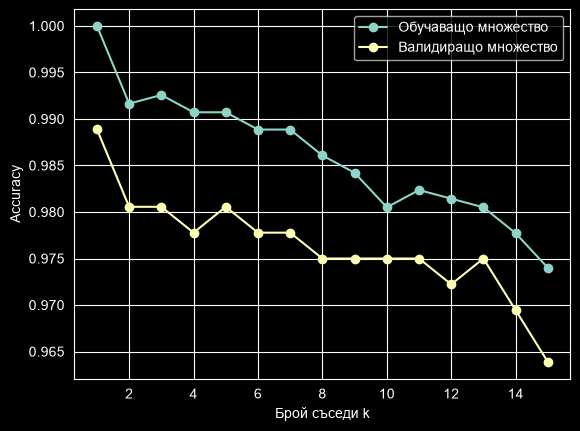

Test accuracy на окончателния модел: 0.9861


In [12]:
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

digits = datasets.load_digits()
X, y = digits.data, digits.target

X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_trainval, y_trainval, test_size=0.25, stratify=y_trainval, random_state=42)

k_values = range(1, 16)
train_scores, val_scores = [], []
for k in k_values:
    model = Pipeline([('scaler', MinMaxScaler()), ('clf', KNeighborsClassifier(n_neighbors=k))])
    model.fit(X_train, y_train)
    train_scores.append(model.score(X_train, y_train))
    val_scores.append(model.score(X_val, y_val))
    print(f"k = {k:2d}: train accuracy = {train_scores[-1]:.4f}, validation accuracy = {val_scores[-1]:.4f}")

# Избор на k по точността върху валидационното множество
best_k = k_values[val_scores.index(max(val_scores))]
print("Най-добра стойност: k =", best_k)

plt.plot(k_values, train_scores, marker='o', label='Обучаващо множество')
plt.plot(k_values, val_scores, marker='o', label='Валидиращо множество')
plt.xlabel('Брой съседи k')
plt.ylabel('Accuracy')
plt.legend()
plt.show()
# Окончателен модел: обучение върху обучаващото и  валидационното множество
final_model = Pipeline([('scaler', MinMaxScaler()), ('clf', KNeighborsClassifier(n_neighbors=best_k))])
final_model.fit(X_trainval, y_trainval)
# Еднократна оценка върху тестовото множество
test_acc = accuracy_score(y_test, final_model.predict(X_test))
print("Test accuracy на окончателния модел:", round(test_acc, 4))

Задача 3

In [10]:
from sklearn import datasets
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

digits = datasets.load_digits()
X, y = digits.data, digits.target

X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Търсене по решетка (Grid Search) за метода на опорните вектори
svm_pipe = Pipeline([('scaler', MinMaxScaler()), ('clf', SVC())])
svm_grid = [
    {'clf__kernel': ['linear'], 'clf__C': [0.1, 1, 10, 100]},
    {'clf__kernel': ['rbf'], 'clf__C': [0.1, 1, 10, 100], 'clf__gamma': [0.001, 0.01, 0.1, 1]}
]
svm_search = GridSearchCV(svm_pipe, svm_grid, cv=5, scoring='accuracy', n_jobs=-1)
svm_search.fit(X_trainval, y_trainval)
print("SVM - най-добри хиперпараметри:", svm_search.best_params_)
print("SVM - средна точност при кръстосана валидация:", round(svm_search.best_score_, 4))

# Случайно търсене (Random Search) за невронната мрежа
mlp_pipe = Pipeline([('scaler', MinMaxScaler()), ('clf', MLPClassifier(max_iter=1000, random_state=42))])
mlp_dist = {
    'clf__hidden_layer_sizes': [(64,), (128,), (64, 32), (128, 64)],
    'clf__alpha': [0.00001, 0.0001, 0.001, 0.01, 0.1],
    'clf__learning_rate_init': [0.001, 0.01, 0.1]
}
mlp_search = RandomizedSearchCV(mlp_pipe, mlp_dist, n_iter=10, cv=5, scoring='accuracy', random_state=42, n_jobs=-1)
mlp_search.fit(X_trainval, y_trainval)
print("MLP - най-добри хиперпараметри:", mlp_search.best_params_)
print("MLP - средна точност при кръстосаната валидация:", round(mlp_search.best_score_, 4))

# Избор на модел по резултата от кръстосаната валидация
if svm_search.best_score_ >= mlp_search.best_score_:
    best_name, best_model = 'SVM', svm_search.best_estimator_
else:
    best_name, best_model = 'MLP', mlp_search.best_estimator_
print("Избран модел:", best_name)

# Еднократна оценка върху тестовото множество
y_pred = best_model.predict(X_test)
print(f"Accuracy of {best_name} on test set: {round(accuracy_score(y_test, y_pred), 4)}")

SVM - най-добри хиперпараметри: {'clf__C': 10, 'clf__gamma': 0.1, 'clf__kernel': 'rbf'}
SVM - средна точност при кръстосана валидация: 0.9882
MLP - най-добри хиперпараметри: {'clf__learning_rate_init': 0.01, 'clf__hidden_layer_sizes': (64,), 'clf__alpha': 0.0001}
MLP - средна точност при кръстосаната валидация: 0.9777
Избран модел: SVM
Accuracy of SVM on test set: 0.9944


Малка gamma (0.001, 0.01) дава недообучение, докато голяма gamma (1) дава преобучение. Всяка точка влияе само на най-близките си съседи, затова разликата между обучаваща и валидационна точност расте и валидационната пада. Най-добри резултати има при gamma = 0.1.

Като крайна оценка на модела вземаме оценката върху тестовото множество, а именно: 0.9944. Това е симулация на реална среда и нови невиждани от модела данни, затова са по-добра отправна точка за оценка.

Задача 4

Признаци с нормално разпределение: 0 от 30
Най-добра стойност на var_smoothing: 1e-11
Accuracy: 0.9357
Classification Error: 0.0643
Precision: 0.9492
Recall: 0.875
F1 Score: 0.9106
Confusion Matrix:
 [[104   3]
 [  8  56]]
ROC AUC Score: 0.993


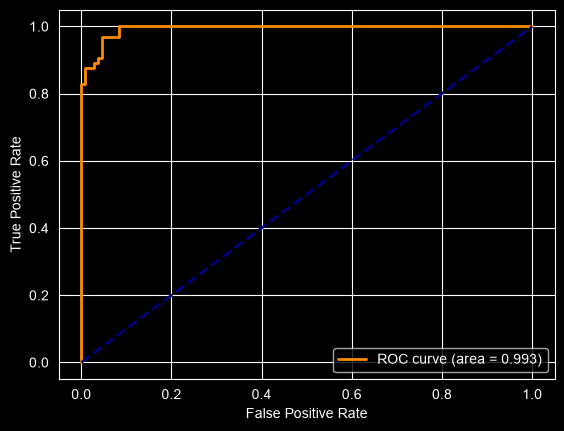

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score, roc_curve, auc
from scipy.stats import shapiro

data = load_breast_cancer()
X = data.data
# Клас Positive (1) = злокачествен тумор; в набора той е с етикет 0
y = (data.target == 0).astype(int)

# Тест на Шапиро-Уилк за всеки признак поотделно
normal_count = 0
for j in range(X.shape[1]):
    stat, p = shapiro(X[:, j])
    if p > 0.05:
        normal_count += 1

print("Признаци с нормално разпределение:", normal_count, "от", X.shape[1])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
# Избор на var_smoothing с кръстосана валидация по метрика recall
param_grid = {'var_smoothing': np.logspace(-12, -2, 11)}
search = GridSearchCV(GaussianNB(), param_grid, cv=5, scoring='recall')
search.fit(X_train, y_train)
print("Най-добра стойност на var_smoothing:", search.best_params_['var_smoothing'])
gnb = search.best_estimator_

y_pred = gnb.predict(X_test)
y_score = gnb.predict_proba(X_test)[:, 1]

# Метрики върху тестовото множество
accuracy = accuracy_score(y_test, y_pred)
error = 1 - accuracy
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
confusion_mat = confusion_matrix(y_test, y_pred)
# ROC кривата се построява с вероятностите y_score
fpr, tpr, thresholds = roc_curve(y_test, y_score)
roc_auc = auc(fpr, tpr)
print("Accuracy:", round(accuracy, 4))
print("Classification Error:", round(error, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))
print("Confusion Matrix:\n", confusion_mat)
print("ROC AUC Score:", round(roc_auc, 4))

plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.3f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc="lower right")
plt.show()

Моделът не е открил 8 тумора, които се виждат от долу вляво на confusion матрицата. Точността 0.9357 не стига като оценка, защото не различава видовете грешки. Затова трябва да се гледа и recall (0.875). Той показва, че около 12.5% от злокачествените случаи остават неоткрити.